# Task 1 — Baseline Pix2Pix on MoNuSeg

**Computer Vision II — Master in Artificial Intelligence (2025/2026)**

This notebook implements a **baseline Pix2Pix** image-to-image translation model
following Isola *et al.* (CVPR, 2017) on the **MoNuSeg** dataset (500 paired
samples, each containing a histopathology image and the corresponding nuclei
binary mask).

**Translation direction:** `label map (binary nuclei mask)  →  realistic histology image`.

Pipeline:
1. Load and process the MoNuSeg dataset (split each PNG into the two halves).
2. Split into train / validation / test (70 / 15 / 15).
3. Define a U-Net generator and a 70×70 PatchGAN discriminator.
4. Train with the Pix2Pix objective: adversarial BCE loss + λ·L1 reconstruction loss.
5. Evaluate on the test split using L1, PSNR, SSIM and FID.

## 1. Imports and configuration

In [1]:
import os
import os
os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")
os.environ.setdefault("OMP_NUM_THREADS", "1")
os.environ.setdefault("MKL_NUM_THREADS", "1")

import random
import time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, Subset
from torchvision import transforms
from torchvision.utils import make_grid

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
print("Device:", DEVICE)

# ---------- Hyperparameters ----------
DATA_DIR     = Path("MoNuSeg")
IMG_SIZE     = 256          # Pix2Pix uses 256x256; MoNuSeg halves are 200x200 -> resize
BATCH_SIZE   = 16
NUM_WORKERS  = 0            # set >0 if running on Linux/Mac; on Windows keep at 0
EPOCHS       = 200
LR           = 2e-4
BETAS        = (0.5, 0.999)
LAMBDA_L1    = 100.0        # weight of the L1 reconstruction loss
NGF          = 64           # base number of generator filters
NDF          = 64           # base number of discriminator filters
SAVE_DIR     = Path("checkpoints_baseline")
SAVE_DIR.mkdir(exist_ok=True)
SAMPLES_DIR  = Path("samples_baseline")
SAMPLES_DIR.mkdir(exist_ok=True)

Device: mps


## 2. Dataset

Each PNG file in `MoNuSeg/` is a horizontally concatenated pair: the **left
half** is the real histopathology image (RGB) and the **right half** is the
corresponding **binary nuclei mask**. We load the file, split the two halves,
resize them to 256×256 and normalize each tensor to the range `[-1, 1]` so the
generator can use a `tanh` output, as in the original Pix2Pix.

In [2]:
class MoNuSegDataset(Dataset):
    """Paired dataset for MoNuSeg.

    Returns (label_map, real_image) tensors in [-1, 1] with shape (3, H, W).
    The label map (binary mask) is replicated to 3 channels so the generator
    has a fixed input-channel count, matching the standard Pix2Pix layout.
    """

    def __init__(self, root: Path, img_size: int = 256):
        self.files = sorted(Path(root).glob("*.png"))
        if len(self.files) == 0:
            raise FileNotFoundError(f"No PNG files found in {root}")
        self.img_size = img_size
        self.to_tensor = transforms.Compose([
            transforms.Resize((img_size, img_size), interpolation=transforms.InterpolationMode.BICUBIC),
            transforms.ToTensor(),                                    # [0, 1]
            transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),   # [-1, 1]
        ])

    def __len__(self):
        return len(self.files)

    def __getitem__(self, idx):
        img = Image.open(self.files[idx]).convert("RGB")
        w, h = img.size
        half = w // 2
        real  = img.crop((0,    0, half, h))   # left  -> realistic histology
        label = img.crop((half, 0, w,    h))   # right -> nuclei mask
        return self.to_tensor(label), self.to_tensor(real)


# Build dataset and 70/15/15 split
full_dataset = MoNuSegDataset(DATA_DIR, img_size=IMG_SIZE)
n_total = len(full_dataset)
n_train = int(0.70 * n_total)
n_val   = int(0.15 * n_total)
n_test  = n_total - n_train - n_val

indices = list(range(n_total))
rng = np.random.default_rng(SEED)
rng.shuffle(indices)
train_idx = indices[:n_train]
val_idx   = indices[n_train:n_train + n_val]
test_idx  = indices[n_train + n_val:]

train_set = Subset(full_dataset, train_idx)
val_set   = Subset(full_dataset, val_idx)
test_set  = Subset(full_dataset, test_idx)

train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=NUM_WORKERS, drop_last=True)
val_loader   = DataLoader(val_set,   batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=NUM_WORKERS)
test_loader  = DataLoader(test_set,  batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=NUM_WORKERS)

print(f"Dataset size: {n_total}")
print(f"  train: {len(train_set)}  | val: {len(val_set)}  | test: {len(test_set)}")
print(f"  batches/epoch (train): {len(train_loader)}")

Dataset size: 500
  train: 350  | val: 75  | test: 75
  batches/epoch (train): 21


### 2.1 Visual sanity check

A few random pairs from the training split to confirm that the left half is the
real histology image and the right half is the nuclei mask.

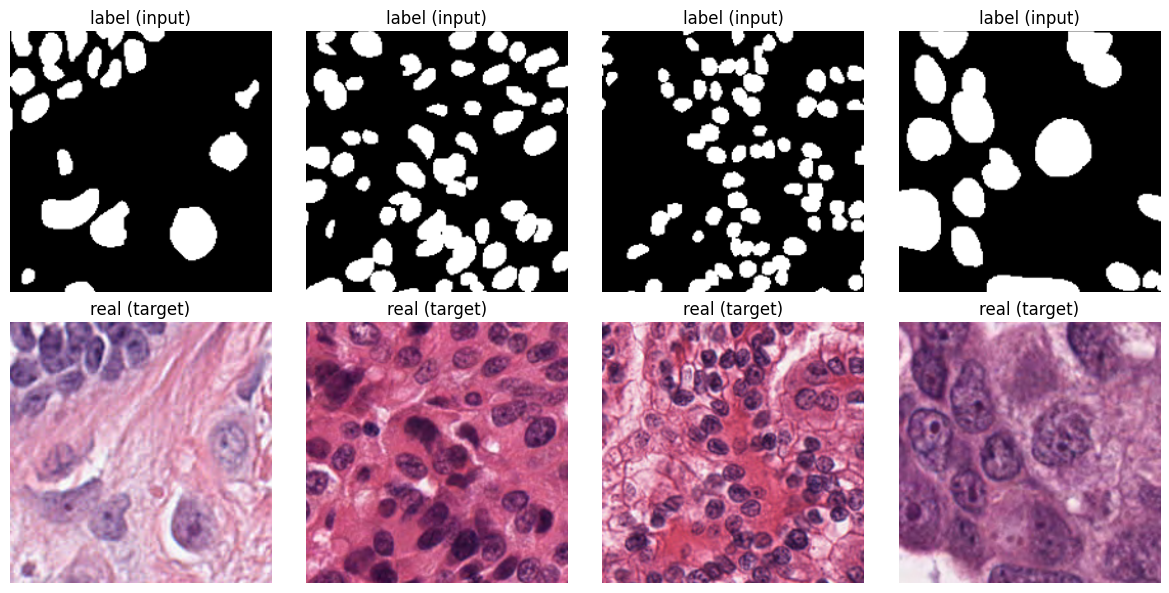

In [3]:
def denorm(t: torch.Tensor) -> torch.Tensor:
    """Map a tensor from [-1, 1] back to [0, 1] for display."""
    return (t.clamp(-1, 1) + 1.0) / 2.0


fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for col in range(4):
    label, real = train_set[col]
    axes[0, col].imshow(denorm(label).permute(1, 2, 0).numpy())
    axes[0, col].set_title(f"label (input)")
    axes[0, col].axis("off")
    axes[1, col].imshow(denorm(real).permute(1, 2, 0).numpy())
    axes[1, col].set_title(f"real (target)")
    axes[1, col].axis("off")
plt.tight_layout()
plt.show()

## 3. Models

### 3.1 U-Net generator

Same encoder–decoder topology as the original Pix2Pix paper: 8 down-sampling
blocks (`Conv → BN → LeakyReLU(0.2)`) and 8 up-sampling blocks
(`ConvTranspose → BN → ReLU`) with skip connections between mirrored layers.
The bottleneck and the three deepest decoder blocks use `Dropout(0.5)` (which
acts as a stochastic noise injection at test time, as proposed by Isola *et al.*).

In [4]:
class UNetDown(nn.Module):
    def __init__(self, in_c, out_c, normalize=True):
        super().__init__()
        layers = [nn.Conv2d(in_c, out_c, kernel_size=4, stride=2, padding=1, bias=not normalize)]
        if normalize:
            layers.append(nn.BatchNorm2d(out_c))
        layers.append(nn.LeakyReLU(0.2, inplace=True))
        self.block = nn.Sequential(*layers)

    def forward(self, x):
        return self.block(x)


class UNetUp(nn.Module):
    def __init__(self, in_c, out_c, dropout=0.0):
        super().__init__()
        layers = [
            nn.ConvTranspose2d(in_c, out_c, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(out_c),
            nn.ReLU(inplace=True),
        ]
        if dropout > 0:
            layers.append(nn.Dropout(dropout))
        self.block = nn.Sequential(*layers)

    def forward(self, x, skip):
        x = self.block(x)
        return torch.cat([x, skip], dim=1)


class UNetGenerator(nn.Module):
    """Standard 8-down / 8-up U-Net for 256x256 inputs."""

    def __init__(self, in_channels=3, out_channels=3, ngf=64):
        super().__init__()
        # Encoder
        self.d1 = UNetDown(in_channels, ngf,        normalize=False)   # 128
        self.d2 = UNetDown(ngf,         ngf * 2)                       # 64
        self.d3 = UNetDown(ngf * 2,     ngf * 4)                       # 32
        self.d4 = UNetDown(ngf * 4,     ngf * 8)                       # 16
        self.d5 = UNetDown(ngf * 8,     ngf * 8)                       # 8
        self.d6 = UNetDown(ngf * 8,     ngf * 8)                       # 4
        self.d7 = UNetDown(ngf * 8,     ngf * 8)                       # 2
        self.d8 = UNetDown(ngf * 8,     ngf * 8, normalize=False)      # 1

        # Decoder (with dropout in the 3 deepest blocks)
        self.u1 = UNetUp(ngf * 8,     ngf * 8, dropout=0.5)
        self.u2 = UNetUp(ngf * 8 * 2, ngf * 8, dropout=0.5)
        self.u3 = UNetUp(ngf * 8 * 2, ngf * 8, dropout=0.5)
        self.u4 = UNetUp(ngf * 8 * 2, ngf * 8)
        self.u5 = UNetUp(ngf * 8 * 2, ngf * 4)
        self.u6 = UNetUp(ngf * 4 * 2, ngf * 2)
        self.u7 = UNetUp(ngf * 2 * 2, ngf)

        self.final = nn.Sequential(
            nn.ConvTranspose2d(ngf * 2, out_channels, kernel_size=4, stride=2, padding=1),
            nn.Tanh(),
        )

    def forward(self, x):
        d1 = self.d1(x);  d2 = self.d2(d1); d3 = self.d3(d2); d4 = self.d4(d3)
        d5 = self.d5(d4); d6 = self.d6(d5); d7 = self.d7(d6); d8 = self.d8(d7)
        u1 = self.u1(d8, d7); u2 = self.u2(u1, d6); u3 = self.u3(u2, d5)
        u4 = self.u4(u3, d4); u5 = self.u5(u4, d3); u6 = self.u6(u5, d2)
        u7 = self.u7(u6, d1)
        return self.final(u7)

### 3.2 PatchGAN discriminator

A 70×70 PatchGAN: it takes the *concatenation* of input (label map) and target
(real or generated) along the channel dimension, and outputs a 30×30 map of
real/fake decisions, each one corresponding to a 70×70 receptive field in the
input.

In [5]:
class PatchGANDiscriminator(nn.Module):
    """70x70 PatchGAN. Input: cat(label, image) -> 6 channels."""

    def __init__(self, in_channels=3, ndf=64):
        super().__init__()

        def block(in_c, out_c, stride=2, normalize=True):
            layers = [nn.Conv2d(in_c, out_c, kernel_size=4, stride=stride,
                                padding=1, bias=not normalize)]
            if normalize:
                layers.append(nn.BatchNorm2d(out_c))
            layers.append(nn.LeakyReLU(0.2, inplace=True))
            return layers

        self.model = nn.Sequential(
            *block(in_channels * 2, ndf,         normalize=False),  # 128
            *block(ndf,             ndf * 2),                       # 64
            *block(ndf * 2,         ndf * 4),                       # 32
            *block(ndf * 4,         ndf * 8, stride=1),             # 31
            nn.Conv2d(ndf * 8, 1, kernel_size=4, stride=1, padding=1),  # 30
        )

    def forward(self, label, img):
        return self.model(torch.cat([label, img], dim=1))


def init_weights(m):
    """Weight init recipe from the Pix2Pix paper: N(0, 0.02)."""
    classname = m.__class__.__name__
    if "Conv" in classname:
        nn.init.normal_(m.weight.data, 0.0, 0.02)
    elif "BatchNorm" in classname:
        nn.init.normal_(m.weight.data, 1.0, 0.02)
        nn.init.constant_(m.bias.data, 0.0)


# Quick architecture sanity check
G = UNetGenerator(ngf=NGF).to(DEVICE)
D = PatchGANDiscriminator(ndf=NDF).to(DEVICE)
G.apply(init_weights);  D.apply(init_weights)

with torch.no_grad():
    dummy = torch.zeros(1, 3, IMG_SIZE, IMG_SIZE, device=DEVICE)
    out_g = G(dummy)
    out_d = D(dummy, out_g)
print("Generator     output:", tuple(out_g.shape))   # (1, 3, 256, 256)
print("Discriminator output:", tuple(out_d.shape))   # (1, 1,  30,  30)
n_params_g = sum(p.numel() for p in G.parameters())
n_params_d = sum(p.numel() for p in D.parameters())
print(f"#params  G: {n_params_g/1e6:.2f} M   D: {n_params_d/1e6:.2f} M")

Generator     output: (1, 3, 256, 256)
Discriminator output: (1, 1, 30, 30)
#params  G: 54.41 M   D: 2.77 M


## 4. Training

The Pix2Pix objective combines a conditional adversarial loss (BCE applied to
the PatchGAN output) and an L1 reconstruction loss between the generated and
the real image.  We follow the original recipe:

* Adam optimizer, `lr = 2e-4`, `betas = (0.5, 0.999)` for both networks.
* λ_L1 = 100 weighting the reconstruction term.
* The discriminator is updated once per generator update.
* Per epoch, we monitor the validation L1 to select the best generator checkpoint.

In [6]:
criterion_gan = nn.BCEWithLogitsLoss()
criterion_l1  = nn.L1Loss()

opt_G = torch.optim.Adam(G.parameters(), lr=LR, betas=BETAS)
opt_D = torch.optim.Adam(D.parameters(), lr=LR, betas=BETAS)


@torch.no_grad()
def validate_l1(generator: nn.Module, loader: DataLoader) -> float:
    """Mean L1 in pixel space (range [0, 1]) over a loader."""
    generator.eval()
    total, n = 0.0, 0
    for label, real in loader:
        label, real = label.to(DEVICE), real.to(DEVICE)
        fake = generator(label)
        # L1 is reported in [0, 1] space to match the metrics block
        total += torch.mean(torch.abs(denorm(fake) - denorm(real))).item() * label.size(0)
        n     += label.size(0)
    generator.train()
    return total / max(n, 1)


@torch.no_grad()
def save_sample_grid(generator: nn.Module, dataset, path: Path, n: int = 6):
    """Save a (label | fake | real) grid for n fixed samples."""
    generator.eval()
    rows = []
    for i in range(n):
        label, real = dataset[i]
        fake = generator(label.unsqueeze(0).to(DEVICE)).squeeze(0).cpu()
        rows.extend([denorm(label), denorm(fake), denorm(real)])
    grid = make_grid(torch.stack(rows), nrow=3, padding=2)
    plt.figure(figsize=(6, 2 * n))
    plt.imshow(grid.permute(1, 2, 0).numpy())
    plt.axis("off"); plt.title("label  |  fake  |  real")
    plt.tight_layout()
    plt.savefig(path, dpi=120, bbox_inches="tight")
    plt.close()
    generator.train()

In [7]:
history = {"g_loss": [], "d_loss": [], "g_gan": [], "g_l1": [], "val_l1": []}
best_val = float("inf")

start = time.time()
for epoch in range(1, EPOCHS + 1):
    G.train(); D.train()
    epoch_g, epoch_d, epoch_gan, epoch_l1 = 0.0, 0.0, 0.0, 0.0

    for label, real in train_loader:
        label = label.to(DEVICE, non_blocking=True)
        real  = real.to(DEVICE,  non_blocking=True)

        # --------- Train discriminator ---------
        opt_D.zero_grad(set_to_none=True)
        with torch.no_grad():
            fake = G(label)

        pred_real = D(label, real)
        pred_fake = D(label, fake)
        loss_d_real = criterion_gan(pred_real, torch.ones_like(pred_real))
        loss_d_fake = criterion_gan(pred_fake, torch.zeros_like(pred_fake))
        loss_d = 0.5 * (loss_d_real + loss_d_fake)
        loss_d.backward()
        opt_D.step()

        # --------- Train generator ---------
        opt_G.zero_grad(set_to_none=True)
        fake = G(label)
        pred_fake_for_g = D(label, fake)
        loss_g_gan = criterion_gan(pred_fake_for_g, torch.ones_like(pred_fake_for_g))
        loss_g_l1  = criterion_l1(fake, real)
        loss_g = loss_g_gan + LAMBDA_L1 * loss_g_l1
        loss_g.backward()
        opt_G.step()

        epoch_g   += loss_g.item()
        epoch_d   += loss_d.item()
        epoch_gan += loss_g_gan.item()
        epoch_l1  += loss_g_l1.item()

    n_batches = len(train_loader)
    history["g_loss"].append(epoch_g   / n_batches)
    history["d_loss"].append(epoch_d   / n_batches)
    history["g_gan"].append (epoch_gan / n_batches)
    history["g_l1"].append  (epoch_l1  / n_batches)

    val_l1 = validate_l1(G, val_loader)
    history["val_l1"].append(val_l1)

    # Best checkpoint by validation L1
    if val_l1 < best_val:
        best_val = val_l1
        torch.save({"G": G.state_dict(), "D": D.state_dict(),
                    "epoch": epoch, "val_l1": val_l1},
                   SAVE_DIR / "best.pt")

    elapsed = time.time() - start
    print(f"epoch {epoch:03d}/{EPOCHS} | "
          f"D {history['d_loss'][-1]:.3f} | "
          f"G {history['g_loss'][-1]:.3f} "
          f"(gan {history['g_gan'][-1]:.3f}, l1 {history['g_l1'][-1]:.3f}) | "
          f"val L1 {val_l1:.4f}  best {best_val:.4f} | "
          f"{elapsed/60:.1f} min")

    if epoch % 10 == 0 or epoch == EPOCHS:
        save_sample_grid(G, val_set, SAMPLES_DIR / f"epoch_{epoch:03d}.png", n=6)

# Final checkpoint
torch.save({"G": G.state_dict(), "D": D.state_dict(),
            "epoch": EPOCHS, "val_l1": history["val_l1"][-1]},
           SAVE_DIR / "last.pt")
print(f"Done. Best val L1 = {best_val:.4f}  (checkpoint: {SAVE_DIR/'best.pt'})")

epoch 001/200 | D 0.776 | G 32.897 (gan 0.939, l1 0.320) | val L1 0.1387  best 0.1387 | 0.3 min
epoch 002/200 | D 0.568 | G 28.794 (gan 1.087, l1 0.277) | val L1 0.1378  best 0.1378 | 0.5 min
epoch 003/200 | D 0.532 | G 28.349 (gan 1.371, l1 0.270) | val L1 0.1341  best 0.1341 | 0.8 min
epoch 004/200 | D 0.407 | G 28.175 (gan 1.589, l1 0.266) | val L1 0.1437  best 0.1341 | 1.0 min
epoch 005/200 | D 0.445 | G 27.219 (gan 1.672, l1 0.255) | val L1 0.1450  best 0.1341 | 1.3 min
epoch 006/200 | D 0.294 | G 26.659 (gan 1.905, l1 0.248) | val L1 0.1598  best 0.1341 | 1.5 min
epoch 007/200 | D 0.267 | G 27.299 (gan 2.042, l1 0.253) | val L1 0.1524  best 0.1341 | 1.7 min
epoch 008/200 | D 0.377 | G 26.762 (gan 2.120, l1 0.246) | val L1 0.1469  best 0.1341 | 2.0 min
epoch 009/200 | D 0.292 | G 26.618 (gan 2.124, l1 0.245) | val L1 0.1552  best 0.1341 | 2.2 min
epoch 010/200 | D 0.251 | G 26.207 (gan 2.050, l1 0.242) | val L1 0.1504  best 0.1341 | 2.5 min
epoch 011/200 | D 0.310 | G 26.050 (gan 

### 4.1 Loss curves

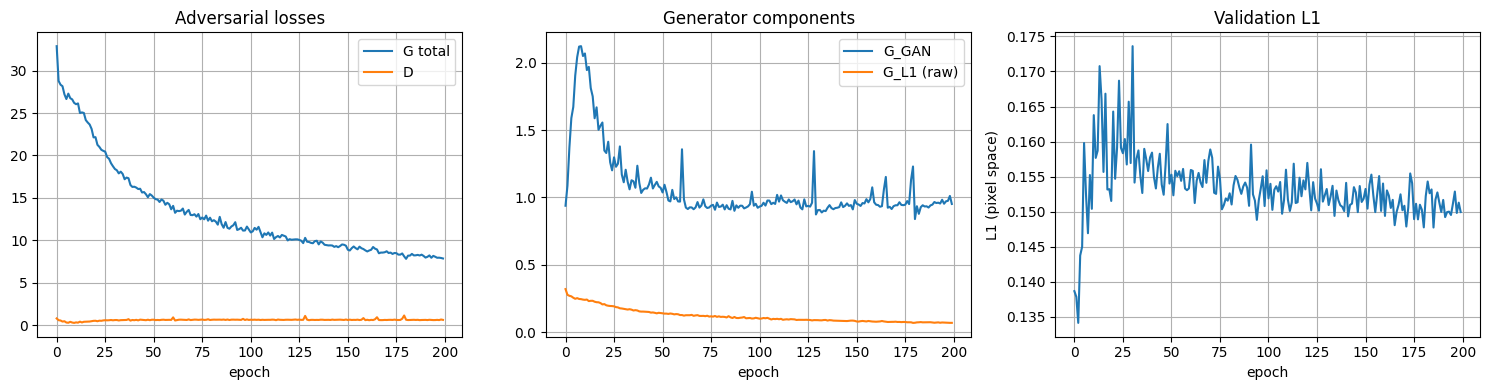

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].plot(history["g_loss"], label="G total")
axes[0].plot(history["d_loss"], label="D")
axes[0].set_xlabel("epoch"); axes[0].set_title("Adversarial losses"); axes[0].legend(); axes[0].grid(True)

axes[1].plot(history["g_gan"], label="G_GAN")
axes[1].plot(history["g_l1"],  label="G_L1 (raw)")
axes[1].set_xlabel("epoch"); axes[1].set_title("Generator components"); axes[1].legend(); axes[1].grid(True)

axes[2].plot(history["val_l1"])
axes[2].set_xlabel("epoch"); axes[2].set_ylabel("L1 (pixel space)")
axes[2].set_title("Validation L1"); axes[2].grid(True)

plt.tight_layout()
plt.show()

## 5. Evaluation on the test set

We load the **best** checkpoint (lowest validation L1) and report on the test
split:

* **L1** (mean absolute error in `[0, 1]`),
* **PSNR** (higher is better),
* **SSIM** (structural similarity, higher is better),
* **FID** (Fréchet Inception Distance, lower is better — perceptual realism).

`torchmetrics` is used for SSIM/PSNR/FID; the cell installs it on the fly if
it's not already available.

In [11]:
try:
    from torchmetrics.image import (
        StructuralSimilarityIndexMeasure,
        PeakSignalNoiseRatio,
    )
    from torchmetrics.image.fid import FrechetInceptionDistance
except ImportError:
    import subprocess, sys
    subprocess.check_call([sys.executable, "-m", "pip", "install",
                           "torchmetrics[image]", "torch-fidelity"])
    from torchmetrics.image import (
        StructuralSimilarityIndexMeasure,
        PeakSignalNoiseRatio,
    )
    from torchmetrics.image.fid import FrechetInceptionDistance


# Reload best generator
ckpt = torch.load(SAVE_DIR / "best.pt", map_location=DEVICE)
G.load_state_dict(ckpt["G"])
G.eval()
print(f"Loaded best generator (epoch {ckpt['epoch']}, val L1 = {ckpt['val_l1']:.4f})")

ssim_metric = StructuralSimilarityIndexMeasure(data_range=1.0).to(DEVICE)
psnr_metric = PeakSignalNoiseRatio(data_range=1.0).to(DEVICE)
fid_metric = FrechetInceptionDistance(feature=2048, normalize=True).to("cpu")

l1_total, n = 0.0, 0
with torch.no_grad():
    for label, real in test_loader:
        label = label.to(DEVICE); real = real.to(DEVICE)
        fake  = G(label)

        # All metrics expect images in [0, 1]
        fake01 = denorm(fake)
        real01 = denorm(real)

        l1_total += torch.mean(torch.abs(fake01 - real01)).item() * label.size(0)
        n        += label.size(0)
        ssim_metric.update(fake01, real01)
        psnr_metric.update(fake01, real01)
        # FID expects uint8-equivalent floats in [0, 1] when normalize=True
        fid_metric.update(real01.to("cpu"), real=True)
        fid_metric.update(fake01.to("cpu"), real=False)

results = {
    "L1":   l1_total / max(n, 1),
    "PSNR": psnr_metric.compute().item(),
    "SSIM": ssim_metric.compute().item(),
    "FID":  fid_metric.compute().item(),
}
print("\nTest-set metrics (baseline Pix2Pix on MoNuSeg)")
print("-" * 48)
for k, v in results.items():
    print(f"  {k:<5}: {v:.4f}")

Loaded best generator (epoch 3, val L1 = 0.1341)

Test-set metrics (baseline Pix2Pix on MoNuSeg)
------------------------------------------------
  L1   : 0.1393
  PSNR : 15.0168
  SSIM : 0.3540
  FID  : 433.0643


### 5.1 Qualitative results

Side-by-side comparison `label  |  generated  |  real` on a handful of test
images.

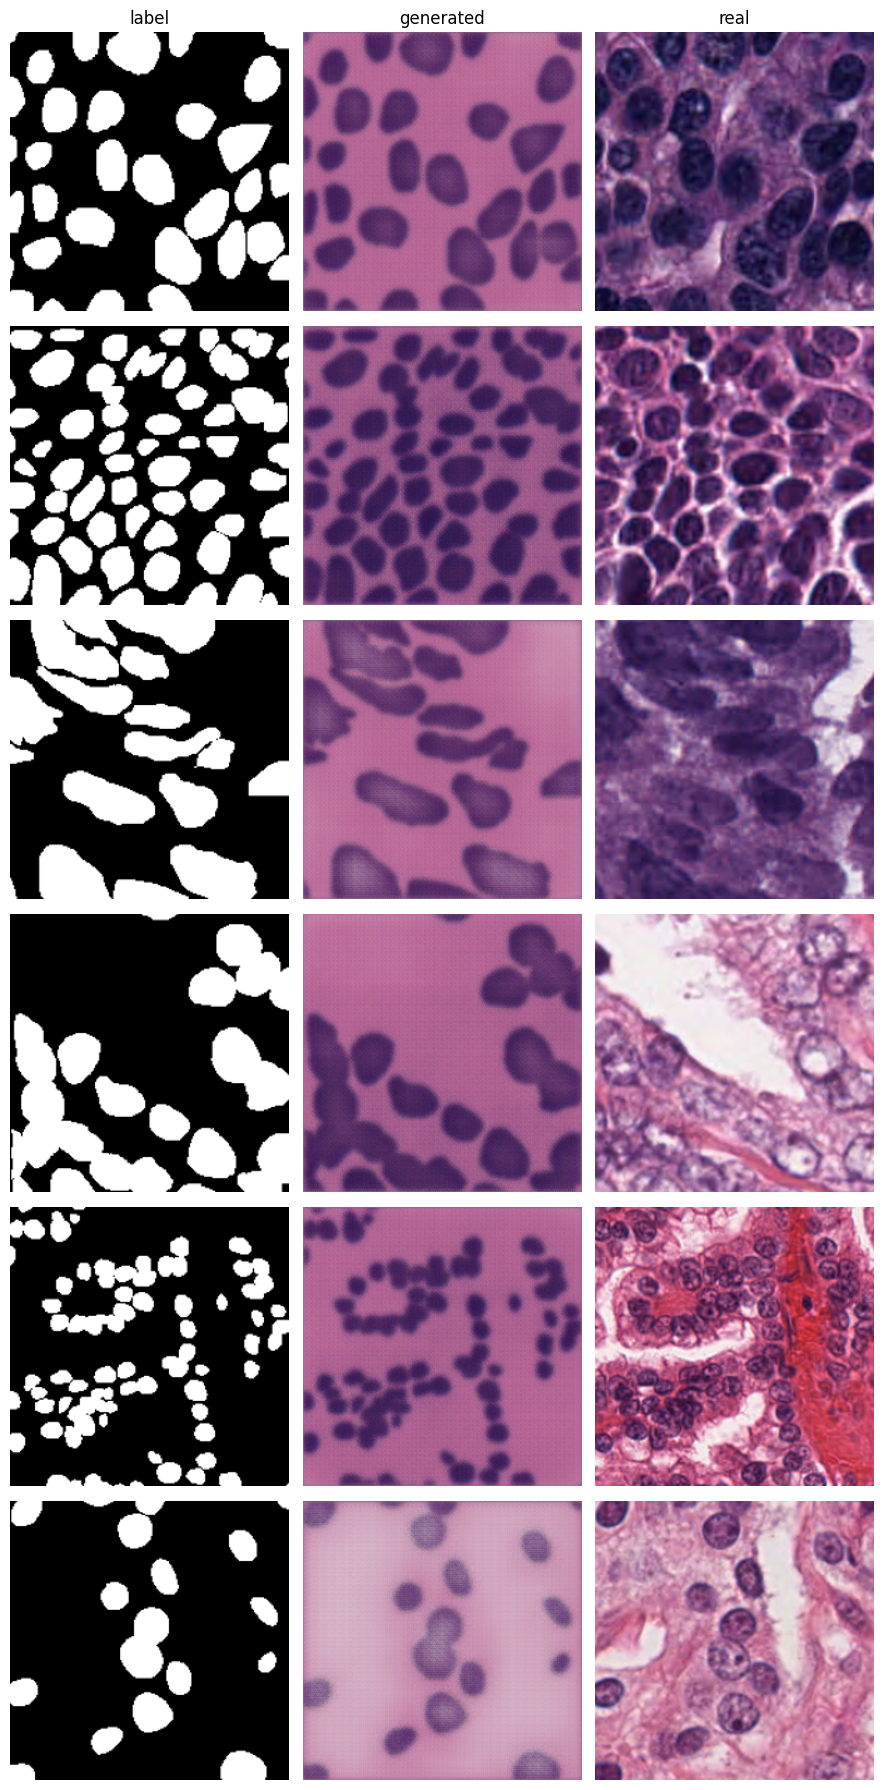

In [12]:
G.eval()
n_show = 6
fig, axes = plt.subplots(n_show, 3, figsize=(9, 3 * n_show))
with torch.no_grad():
    for i in range(n_show):
        label, real = test_set[i]
        fake = G(label.unsqueeze(0).to(DEVICE)).squeeze(0).cpu()
        for j, (img, title) in enumerate([
            (denorm(label), "label"),
            (denorm(fake),  "generated"),
            (denorm(real),  "real"),
        ]):
            axes[i, j].imshow(img.permute(1, 2, 0).numpy())
            axes[i, j].axis("off")
            if i == 0:
                axes[i, j].set_title(title)
plt.tight_layout()
plt.savefig(SAMPLES_DIR / "test_qualitative.png", dpi=120, bbox_inches="tight")
plt.show()

### 5.2 Persist the metrics

Save the test-set metrics as a small JSON next to the checkpoints — this file
is the artefact that Task 2 will compare against.

In [13]:
import json

summary = {
    "dataset": "MoNuSeg",
    "model":   "Pix2Pix baseline (U-Net + 70x70 PatchGAN)",
    "epochs":  EPOCHS,
    "img_size": IMG_SIZE,
    "batch_size": BATCH_SIZE,
    "lambda_l1": LAMBDA_L1,
    "best_epoch": int(ckpt["epoch"]),
    "test_metrics": {k: float(v) for k, v in results.items()},
}
with open(SAVE_DIR / "test_metrics.json", "w") as f:
    json.dump(summary, f, indent=2)
print("Saved", SAVE_DIR / "test_metrics.json")
print(json.dumps(summary, indent=2))

Saved checkpoints_baseline/test_metrics.json
{
  "dataset": "MoNuSeg",
  "model": "Pix2Pix baseline (U-Net + 70x70 PatchGAN)",
  "epochs": 200,
  "img_size": 256,
  "batch_size": 16,
  "lambda_l1": 100.0,
  "best_epoch": 3,
  "test_metrics": {
    "L1": 0.1392726973692576,
    "PSNR": 15.016788482666016,
    "SSIM": 0.3539634943008423,
    "FID": 433.06427001953125
  }
}
